# **Практическая работа №5. Работа с растровыми данными в Rasterio**

---

**Данные для обработки:**

- Одноканальное изображение (ЦМР): https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif
- Мультиспектральное изображение (Landsat): https://github.com/opengeos/datasets/releases/download/raster/cog.tif

In [1]:
%%capture
%pip install rasterio numpy matplotlib

In [2]:
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlretrieve
import rasterio
from rasterio.plot import show
from rasterio.windows import Window
from rasterio.warp import calculate_default_transform, reproject, Resampling
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'axes.titlesize': 15, 'axes.titleweight': 'bold',
                     'axes.labelsize': 11, 'figure.dpi': 110})

# Загружаем исходные данные из задания во временную папку.
temp_data = TemporaryDirectory()
data_folder = Path(temp_data.name)
dem_path = data_folder / 'dem_90m.tif'
multi_path = data_folder / 'cog.tif'
_ = urlretrieve('https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif', dem_path)
_ = urlretrieve('https://github.com/opengeos/datasets/releases/download/raster/cog.tif', multi_path)

### **Задание 1. Чтение и исследование растровых данных**



1. Откройте одноканальное изображение ЦМР с использованием `rasterio`.


In [3]:
dem = rasterio.open(dem_path)
print('Открыт файл:', dem_path.name)

Открыт файл: dem_90m.tif


2. Извлеките и выведите метаданные растра, включая СК, разрешение, границы, количество каналов и типы данных.


In [4]:
print('Формат:', dem.driver)
print('СК:', dem.crs)
print('Разрешение:', dem.res)
print('Границы:', dem.bounds)
print('Количество каналов:', dem.count)
print('Типы данных:', dem.dtypes)
print('Геопривязка:')
print(dem.transform)

Формат: GTiff
СК: EPSG:3857
Разрешение: (90.0, 89.99579177642138)
Границы: BoundingBox(left=-13442488.3428, bottom=4388214.6777, right=-13058278.3428, top=4668371.5775)
Количество каналов: 1
Типы данных: ('int16',)
Геопривязка:
| 90.00, 0.00,-13442488.34|
| 0.00,-90.00, 4668371.58|
| 0.00, 0.00, 1.00|


3. Отобразите ширину и высоту растра, а также типы данных пикселей, чтобы понять размеры сетки и структуру данных.

In [5]:
print('Ширина:', dem.width, 'пикселей')
print('Высота:', dem.height, 'пикселей')
print('Тип пикселей:', dem.dtypes[0])

Ширина: 4269 пикселей
Высота: 3113 пикселей
Тип пикселей: int16


---



### **Задание 2. Визуализация и манипулирование растровыми каналами**



1. Визуализируйте одноканальное изображение ЦМР с использованием пользовательской цветовой карты (например, cmap='terrain').


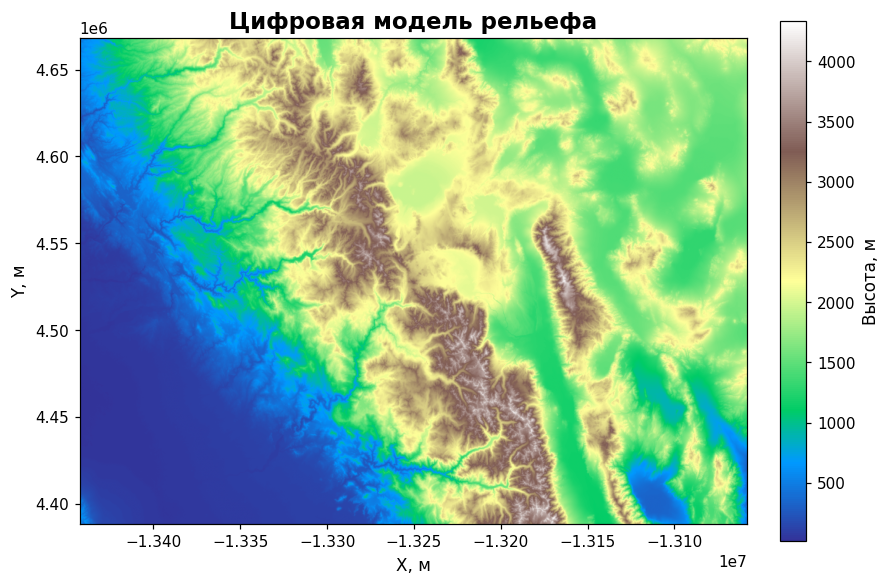

In [6]:
dem_data = dem.read(1, masked=True)

fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')
show(dem_data, transform=dem.transform, cmap='terrain', ax=ax,
     title='Цифровая модель рельефа')
ax.set_xlabel('X, м')
ax.set_ylabel('Y, м')
fig.colorbar(ax.images[0], ax=ax, label='Высота, м', shrink=0.8)
plt.show()

2. Откройте мультиспектральное изображение и визуализируйте первый канал с использованием подходящей цветовой карты.


Количество каналов: 4
Размер: 343 × 206 пикселей


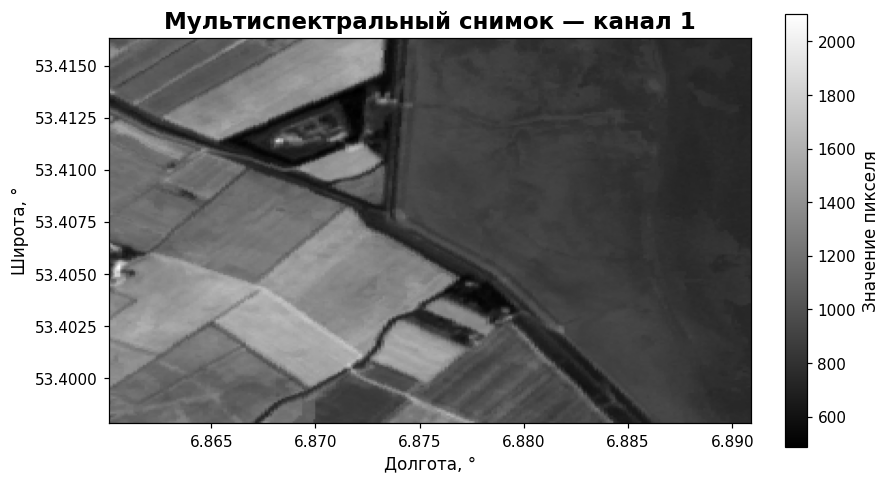

In [7]:
multi = rasterio.open(multi_path)
print('Количество каналов:', multi.count)
print('Размер:', multi.width, '×', multi.height, 'пикселей')

fig, ax = plt.subplots(figsize=(8, 5), layout='constrained')
show((multi, 1), cmap='gray', ax=ax, title='Мультиспектральный снимок — канал 1')
ax.set_xlabel('Долгота, °')
ax.set_ylabel('Широта, °')
fig.colorbar(ax.images[0], ax=ax, label='Значение пикселя', shrink=0.8)
plt.show()

3. Объедините несколько каналов из мультиспектрального изображения (например, Красный, Зеленый и Синий) и совместите их в один массив для создания RGB-композитного изображения.

>*Примечание:*
>
> При работе с многоканальными растровыми изображениями, особенно в формате COG.TIFF (Cloud Optimized GeoTIFF), может возникнуть проблема с некорректным отображением псевдоцветного изображения. Это связано с тем, что разные каналы могут иметь различные диапазоны значений пикселей.
>
> Для корректной визуализации на шаге 2 необходимо применить нормализацию к каждому каналу перед отображением.



Включите следующую функцию в ваш код:

```python
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm
```

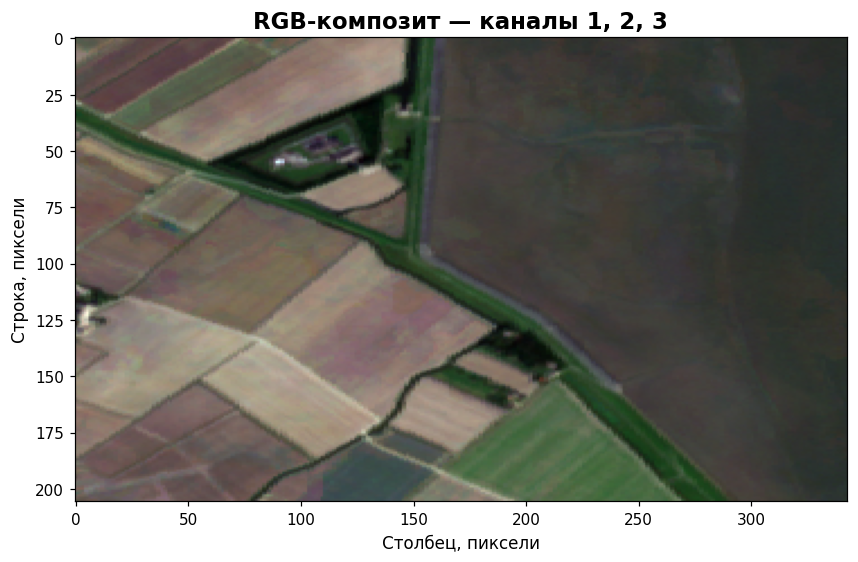

In [8]:
def normalize(band):
    band = band.astype('float32')
    band_min = band.min()
    band_max = band.max()
    if band_max == band_min:
        return np.zeros_like(band)
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm


# Для этого файла: Red — 1, Green — 2, Blue — 3, NIR — 4.
# Исходный пример: https://leafmap.org/notebooks/47_numpy_to_cog/
red_band = normalize(multi.read(1))
green_band = normalize(multi.read(2))
blue_band = normalize(multi.read(3))
rgb = np.dstack((red_band, green_band, blue_band))

plt.figure(figsize=(8, 5), layout='constrained')
plt.imshow(rgb)
plt.title('RGB-композит — каналы 1, 2, 3')
plt.xlabel('Столбец, пиксели')
plt.ylabel('Строка, пиксели')
plt.show()

---



### **Задание 3. Обрезка растра с использованием индексации массива**



1. Откройте мультиспектральное изображение и обрежьте его с использованием спискового среза (указав диапазоны строк и столбцов).


In [9]:
# Обрезаем все каналы по строкам и столбцам.
data = multi.read()
row_start, row_stop = 50, 150
col_start, col_stop = 50, 200
subset = data[:, row_start:row_stop, col_start:col_stop]

print('Исходный массив (каналы, строки, столбцы):', data.shape)
print('Обрезанный массив:', subset.shape)

Исходный массив (каналы, строки, столбцы): (4, 206, 343)
Обрезанный массив: (4, 100, 150)


2. Визуализируйте обрезанную часть изображения с использованием matplotlib, чтобы убедиться в корректном результате.


>*Примечание:*
>
> При работе с многоканальными растровыми изображениями, особенно в формате COG.TIFF (Cloud Optimized GeoTIFF), может возникнуть проблема с некорректным отображением псевдоцветного изображения. Это связано с тем, что разные каналы могут иметь различные диапазоны значений пикселей.
>
> Для корректной визуализации на шаге 2 необходимо применить нормализацию к каждому каналу перед отображением.



Включите следующую функцию в ваш код:

```python
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm
```

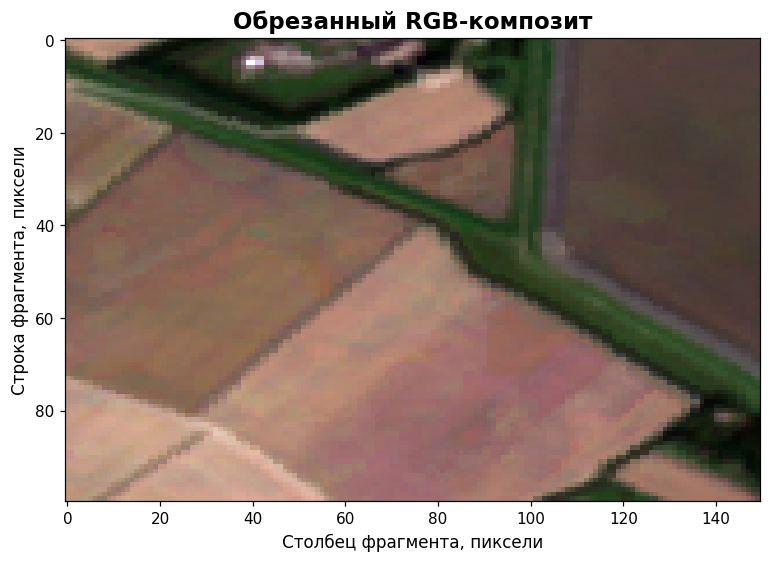

In [10]:
rgb_subset = np.dstack((normalize(subset[0]),
                        normalize(subset[1]),
                        normalize(subset[2])))

plt.figure(figsize=(8, 5), layout='constrained')
plt.imshow(rgb_subset)
plt.title('Обрезанный RGB-композит')
plt.xlabel('Столбец фрагмента, пиксели')
plt.ylabel('Строка фрагмента, пиксели')
plt.show()

3. Сохраните обрезанное подмножество растра в новый файл с именем `clipped_multispectral.tif`.

In [11]:
# Смещаем геопривязку к левому верхнему углу фрагмента.
window = Window(col_start, row_start, col_stop - col_start, row_stop - row_start)
clip_profile = multi.profile.copy()
clip_profile.update(height=subset.shape[1], width=subset.shape[2],
                    transform=multi.window_transform(window), compress='lzw')

with rasterio.open('clipped_multispectral.tif', 'w', **clip_profile) as dst:
    dst.write(subset)

print('Сохранено: clipped_multispectral.tif')

Сохранено: clipped_multispectral.tif


---



### **Задание 4. Вычисление NDWI (калькуляция каналов)**



1. Откройте мультиспектральное изображение и извлеките каналы Green (Зеленый) и Ближний инфракрасный (NIR).


In [12]:
# В этом четырёхканальном файле Green — канал 2, NIR — канал 4.
green = multi.read(2, masked=True).astype('float32').filled(np.nan)
nir = multi.read(4, masked=True).astype('float32').filled(np.nan)
print('Размер каналов Green и NIR:', green.shape)

Размер каналов Green и NIR: (206, 343)


2. Вычислите Нормализованный разностный водный индекс ([NDWI](https://en.wikipedia.org/wiki/Normalized_difference_water_index)) по формуле:

    NDWI = (Green - NIR) / (Green + NIR)

In [13]:
denominator = green + nir
valid = np.isfinite(green) & np.isfinite(nir) & (denominator != 0)

# Пустые пиксели и деление на ноль не участвуют в расчёте.
ndwi_nodata = -9999.0
ndwi = np.full(green.shape, ndwi_nodata, dtype='float32')
np.divide(green - nir, denominator, out=ndwi, where=valid)

print('Минимум NDWI:', round(float(ndwi[valid].min()), 3))
print('Максимум NDWI:', round(float(ndwi[valid].max()), 3))

Минимум NDWI: -0.622
Максимум NDWI: 0.477


3. Визуализируйте результат NDWI с использованием цветовой карты, подходящей для воды (например, cmap='Blues'), чтобы выделить водные объекты.


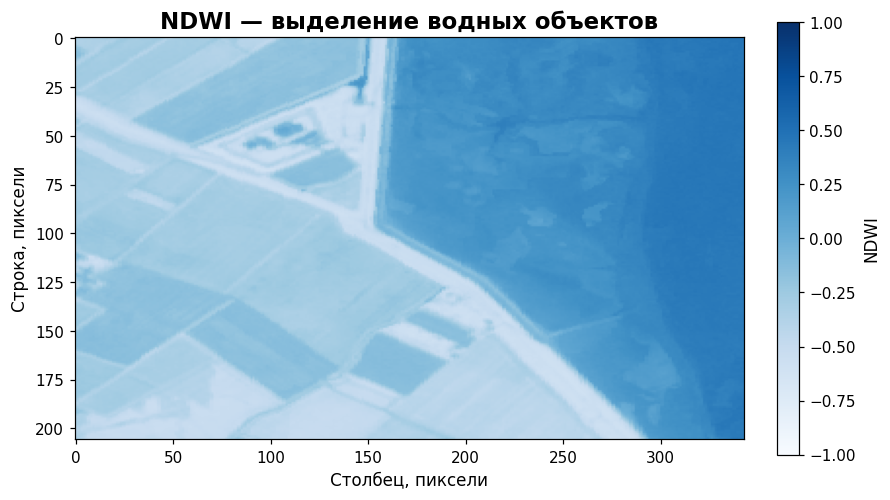

In [14]:
plt.figure(figsize=(8, 5), layout='constrained')
plt.imshow(np.ma.masked_equal(ndwi, ndwi_nodata), cmap='Blues', vmin=-1, vmax=1)
plt.title('NDWI — выделение водных объектов')
plt.xlabel('Столбец, пиксели')
plt.ylabel('Строка, пиксели')
plt.colorbar(label='NDWI', shrink=0.8)
plt.show()



4. Сохраните полученное изображение NDWI как новый растровый файл с именем ndwi.tif.

In [15]:
# Индекс сохраняем одним вещественным каналом с исходной геопривязкой.
ndwi_profile = multi.profile.copy()
ndwi_profile.update(count=1, dtype='float32', nodata=ndwi_nodata, compress='lzw')

with rasterio.open('ndwi.tif', 'w', **ndwi_profile) as dst:
    dst.write(ndwi, 1)

print('Сохранено: ndwi.tif')

Сохранено: ndwi.tif


---



### **Задание 5. Перепроецирование растровых данных**



1. Перепроецируйте одноканальный растр ЦМР из его исходной СК в EPSG:4326 (WGS 84) с использованием функции `rasterio.warp.reproject`.


In [16]:
dst_crs = 'EPSG:4326'
dst_transform, dst_width, dst_height = calculate_default_transform(
    dem.crs, dst_crs, dem.width, dem.height, *dem.bounds
)

# Пустые места новой сетки отмечаем отдельным значением.
dem_nodata = -32768
reprojected = np.full((dst_height, dst_width), dem_nodata, dtype=dem.dtypes[0])
reproject(
    source=rasterio.band(dem, 1),
    destination=reprojected,
    src_transform=dem.transform,
    src_crs=dem.crs,
    dst_transform=dst_transform,
    dst_crs=dst_crs,
    dst_nodata=dem_nodata,
    resampling=Resampling.nearest,
)

print('Исходная СК:', dem.crs)
print('Новая СК:', dst_crs)
print('Размер новой сетки:', dst_width, '×', dst_height, 'пикселей')

Исходная СК: EPSG:3857
Новая СК: EPSG:4326
Размер новой сетки: 4575 × 2642 пикселей


2. Сохраните перепроецированный растр в новый файл GeoTIFF с именем `reprojected_dem.tif`.


In [17]:
reprojected_profile = dem.profile.copy()
reprojected_profile.update(crs=dst_crs, transform=dst_transform,
                           width=dst_width, height=dst_height,
                           nodata=dem_nodata, compress='lzw')

with rasterio.open('reprojected_dem.tif', 'w', **reprojected_profile) as dst:
    dst.write(reprojected, 1)

print('Сохранено: reprojected_dem.tif')

Сохранено: reprojected_dem.tif


3. Визуализируйте как исходный, так и перепроецированный наборы данных ЦМР, чтобы сравнить, как перепроецирование влияет на пространственное покрытие и разрешение.

Исходная ЦМР:
Разрешение: (90.0, 89.99579177642138) м
Границы: BoundingBox(left=-13442488.3428, bottom=4388214.6777, right=-13058278.3428, top=4668371.5775)
После перепроецирования:
Разрешение: (0.0007543273324700005, 0.0007543273324700005) градусов
Границы: BoundingBox(left=-120.75592734935736, bottom=36.63399062180265, right=-117.30487980330712, top=38.62692343418839)


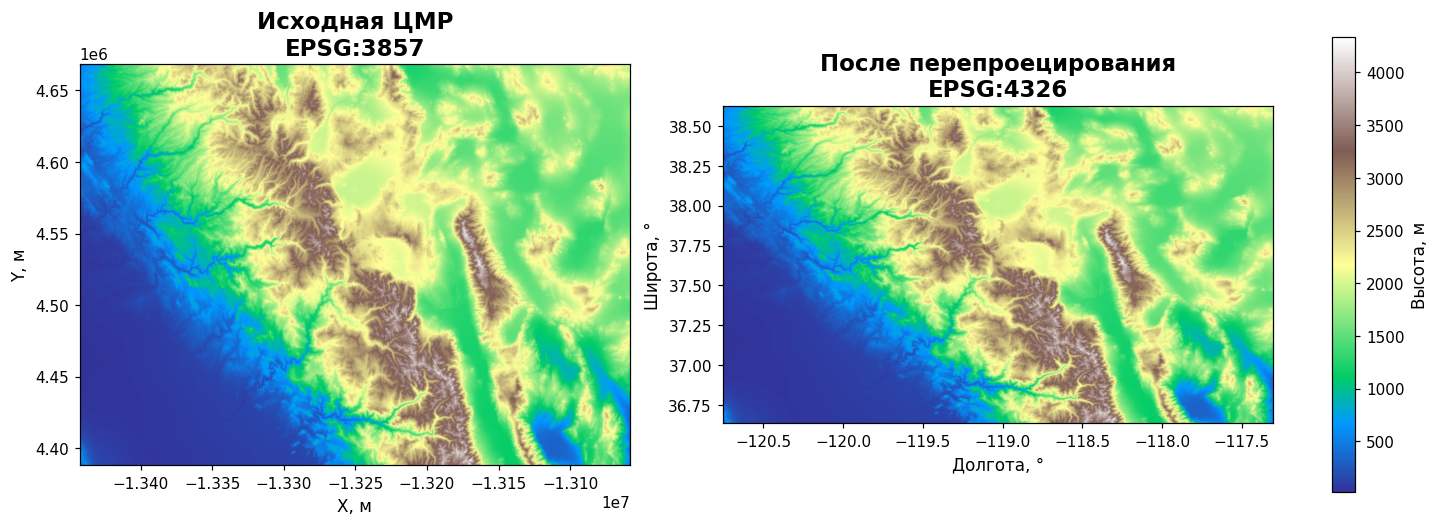

In [18]:
with rasterio.open('reprojected_dem.tif') as result:
    print('Исходная ЦМР:')
    print('Разрешение:', dem.res, 'м')
    print('Границы:', dem.bounds)
    print('После перепроецирования:')
    print('Разрешение:', result.res, 'градусов')
    print('Границы:', result.bounds)

    fig, axes = plt.subplots(1, 2, figsize=(13, 6), layout='constrained')
    limits = {'vmin': float(dem_data.min()), 'vmax': float(dem_data.max())}
    show(dem_data, transform=dem.transform, cmap='terrain', ax=axes[0],
         title='Исходная ЦМР\nEPSG:3857', **limits)
    show(result.read(1, masked=True), transform=result.transform,
         cmap='terrain', ax=axes[1], title='После перепроецирования\nEPSG:4326', **limits)
    axes[0].set_xlabel('X, м')
    axes[0].set_ylabel('Y, м')
    axes[1].set_xlabel('Долгота, °')
    axes[1].set_ylabel('Широта, °')
    fig.colorbar(axes[0].images[0], ax=axes, label='Высота, м', shrink=0.7)
    plt.show()

dem.close()
multi.close()

Территория сохранилась, координаты и размер пикселя теперь заданы в градусах. Размеры растровой сетки изменились.

---